# Choosing the postfilter cutoff

Picks the per-half-year frequency cutoff for the **postfilter** in
`filter.py` / `freq_matrix.py`, using an **unfiltered** frequency matrix
(one built with `--no-postfilter`).

## What the postfilter actually is

The postfilter is a **noise floor**, not a euphemism decision. The real
euphemism detection happens downstream (hit matrix, hit rate, cosine drift,
pilot selection). The floor exists only to drop words that appear so rarely
in a half-year that any hit-rate computed on them (`hits_k / frequency`)
would be statistical noise.

So we evaluate two rule *forms* side by side, both applied per half-year
(leakage-safe — each cell's keep/null decision uses only its own
half-year):

1. **Absolute floor** (the shipped gate). Keep a cell if its raw count
   `>= C`. Justified on **statistical-reliability** grounds: a rate needs a
   minimum denominator to be stable, and that minimum is an absolute count,
   independent of corpus size. This is why a single number is defensible
   here even though the corpus grows over time.
2. **Rate floor** (a diagnostic / alternative). Keep a cell if its count
   `>= R` per million tokens of *that half-year*. Measures **prominence**
   and is intrinsically corpus-size-normalized.

## On leakage

A per-half-year cutoff is **not** future-looking as long as each
half-year's cutoff is computed from that half-year's own data (its count
distribution and token total). An absolute floor leaks only in the weakest
sense: the *number* could encode timeline-wide judgement if you pick it by
eyeballing a pooled survivor curve. The fix is to justify the absolute floor
on **power** grounds (minimum N for a stable proportion), not on a
pooled-curve knee. This notebook therefore reports distributions **to
inform** the choice, but recommends a floor you can defend on power grounds,
and uses the rate columns only to show how consistently that floor behaves
across half-years.

## Outputs

- Per-half-year nonzero-count distribution (quantiles).
- Survivors vs. absolute floor, per half-year, + the implied rate/M.
- Survivors vs. rate floor, per half-year, + the implied absolute count.
- Recall check: how many known drug terms each floor would drop, per
  half-year (recall-oriented filter — this is the deciding table).
- Survivor curves (plots).

## Config

Point `FREQ_DIR` at the directory holding the **unfiltered** matrix
(`freq.npy`, `freq_half_years.csv`, `freq_words.csv`, `freq_totals.csv`),
i.e. the output of a `--no-postfilter` build. Set `STEM` if you used a
non-default `--stem`.

In [31]:
from pathlib import Path

# TODO: set this to your unfiltered (--no-postfilter) matrix directory.
FREQ_DIR = Path(".")
STEM = "freq"

# Directory holding the known-term lists for the recall check.
WORD_LISTS_DIR = Path(
    "/home/hice1/kli605/scratch/Emerging-and-New-Euphemism-Detection/data_collection/word_lists"
)

# Path to the shared `filter.py` (the real prefilter reused by the recall
# check). Set this to your repo's `shared_utils/filter.py`.
FILTER_PY = Path(
    "/home/hice1/kli605/scratch/Emerging-and-New-Euphemism-Detection/filter.py"
)

# Lists to run the recall check on: {name: filename under WORD_LISTS_DIR}.
# Each is loaded, normalized, and checked against every candidate floor. A
# file that doesn't exist is skipped with a warning.
RECALL_LISTS = {
    "drug_synonyms": "drug_synonyms.txt",
    "candidates": "candidate_words.txt",
    "all_dea": "all_dea_slang.txt"
}

# Candidate absolute floors (raw count in a half-year).
ABS_FLOORS = [10, 20, 30, 50, 100]

# Candidate rate floors (occurrences per million tokens in a half-year).
RATE_FLOORS = [0.25, 0.5, 1.0, 2.0]

# Quantiles reported for the nonzero-count distribution per half-year.
QUANTILES = [0.5, 0.75, 0.9, 0.95, 0.99]

In [29]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

# Reuse the real prefilter so the recall check attributes drops to the
# exact same rules the matrix build applies (short / multi-word / stop
# word). Load it directly from FILTER_PY.
_filter_py = Path(FILTER_PY).expanduser().resolve()
if not _filter_py.exists():
    raise RuntimeError(
        f"FILTER_PY={_filter_py} not found. Set it to your repo's "
        "shared_utils/filter.py in the config cell."
    )
if str(_filter_py.parent) not in sys.path:
    sys.path.insert(0, str(_filter_py.parent))

from filter import (  # noqa: E402
    MAX_WORDS,
    MIN_TERM_LENGTH,
    prefilter,
)

print(
    f"prefilter loaded from {_filter_py} "
    f"(MIN_TERM_LENGTH={MIN_TERM_LENGTH}, MAX_WORDS={MAX_WORDS})"
)

prefilter loaded from /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/filter.py (MIN_TERM_LENGTH=4, MAX_WORDS=1)


## Load the unfiltered matrix

`freq` is `[half_years, words]` of raw counts. Rows line up with
`half_years`, columns with `words`. We mmap the matrix so a ~1M-column
array doesn't have to fit in RAM twice.

In [36]:
freq = np.load(FREQ_DIR / f"{STEM}.npy", mmap_mode="r")
half_years = pd.read_csv(FREQ_DIR / f"{STEM}_half_years.csv")[
    "half_year"
].tolist()
words = pd.read_csv(FREQ_DIR / f"{STEM}_words.csv")["word"].tolist()
totals = pd.read_csv(FREQ_DIR / f"{STEM}_totals.csv")

assert freq.shape == (len(half_years), len(words)), (
    f"matrix {freq.shape} does not match labels "
    f"({len(half_years)} half-years, {len(words)} words)"
)

# Per-half-year token totals, aligned to the matrix row order. Prefer the
# pre-filter token count; fall back to the matrix row sum if the column is
# missing or zero (an unfiltered build's row sum equals total kept tokens).
tot_by_hy = dict(zip(totals["half_year"], totals["total_tokens"]))
row_tokens = np.array(
    [tot_by_hy.get(h, 0) for h in half_years], dtype=np.float64
)
row_sums = np.asarray(freq.sum(axis=1), dtype=np.float64)
missing_tokens = row_tokens <= 0
if missing_tokens.any():
    row_tokens[missing_tokens] = row_sums[missing_tokens]

print(f"matrix: {freq.shape[0]} half-years x {freq.shape[1]:,} words")
print(f"dtype:  {freq.dtype}")
print(f"first/last half-year: {half_years[0]} .. {half_years[-1]}")

matrix: 24 half-years x 5,431,062 words
dtype:  int32
first/last half-year: 2015H1 .. 2026H2


## 1. Per-half-year count distribution

Quantiles of the **nonzero** cell counts in each half-year. Zero cells are
excluded because they just mean the word didn't occur that half-year, not
that it occurred rarely. `n_words_present` is how many words have any
occurrence in the half-year; `tokens` is that half-year's total token
count (the denominator for the rate view).

In [37]:
rows = []
for i, h in enumerate(half_years):
    row = np.asarray(freq[i], dtype=np.int64)
    nz = row[row > 0]
    rec = {
        "half_year": h,
        "tokens": int(row_tokens[i]),
        "n_words_present": int(nz.size),
    }
    if nz.size:
        qs = np.quantile(nz, QUANTILES)
        for q, v in zip(QUANTILES, qs):
            rec[f"p{int(q * 100)}"] = float(v)
        rec["max"] = int(nz.max())
    rows.append(rec)

dist = pd.DataFrame(rows).set_index("half_year")
dist

,tokens,n_words_present,p50,p75,p90,p95,p99,max
half_year,,,,,,,,
2015H1,80514513,327464,1.0,4.0,22.0,91.0,1318.00,436912
2015H2,92348765,352123,1.0,4.0,22.0,90.0,1391.78,504373
2016H1,104889357,363437,1.0,4.0,22.0,94.0,1499.00,564434
2016H2,123972409,394834,1.0,3.0,22.0,94.0,1559.00,663117
2017H1,134440404,458003,1.0,3.0,17.0,75.0,1346.00,725921
2017H2,138551804,527172,1.0,2.0,13.0,57.0,1115.29,741771
2018H1,160369869,535439,1.0,3.0,14.0,62.0,1258.00,851400
2018H2,175377764,572794,1.0,2.0,13.0,58.0,1243.00,932821
2019H1,204112789,641047,1.0,2.0,12.0,52.0,1192.00,1104396


## 2. Absolute floor: survivors per half-year

For each candidate absolute floor `C`, how many words survive in each
half-year (count `>= C`), and `rate_per_M` = the rate that floor corresponds
to in that half-year (`C / tokens * 1e6`). The `rate_per_M` column is the
key leakage/consistency diagnostic: if a single `C` implies wildly
different rates across half-years, the absolute floor is behaving very
differently in early vs. recent half-years.

In [38]:
def survivors_abs(floor):
    """Per-half-year survivor count at an absolute floor (count >= floor)."""
    out = np.empty(len(half_years), dtype=np.int64)
    for i in range(len(half_years)):
        row = np.asarray(freq[i], dtype=np.int64)
        out[i] = int((row >= floor).sum())
    return out


abs_frames = []
for c in ABS_FLOORS:
    surv = survivors_abs(c)
    rate = c / np.where(row_tokens > 0, row_tokens, np.nan) * 1e6
    abs_frames.append(
        pd.DataFrame(
            {
                "half_year": half_years,
                "floor": c,
                "survivors": surv,
                "rate_per_M": rate,
            }
        )
    )

abs_long = pd.concat(abs_frames, ignore_index=True)

# Wide survivor table: one column per floor, one row per half-year.
abs_survivors = abs_long.pivot(
    index="half_year", columns="floor", values="survivors"
)
abs_survivors.columns = [f"C>={c}" for c in abs_survivors.columns]
print("Survivors per half-year at each absolute floor:")
abs_survivors

Survivors per half-year at each absolute floor:


,C>=10,C>=20,C>=30,C>=50,C>=100
half_year,,,,,
2015H1,49362,34919,28646,22192,15611
2015H2,52499,37228,30529,23784,16778
2016H1,54413,38690,31855,24882,17693
2016H2,58634,41769,34349,26988,19212
2017H1,60737,43068,35481,27883,19928
2017H2,61306,43456,35695,28066,20001
2018H1,65032,46057,37948,29806,21432
2018H2,67481,47668,39311,30838,22277
2019H1,71805,50531,41612,32685,23585


In [39]:
# Implied rate-per-million for each absolute floor, per half-year.
# A near-constant column across half-years = the floor behaves consistently;
# a steeply shrinking column = the floor is much stricter (in rate terms) in
# the big recent half-years.
abs_rate = abs_long.pivot(
    index="half_year", columns="floor", values="rate_per_M"
)
abs_rate.columns = [f"C>={c}" for c in abs_rate.columns]
print("Implied rate-per-million for each absolute floor:")
abs_rate.round(3)

Implied rate-per-million for each absolute floor:


,C>=10,C>=20,C>=30,C>=50,C>=100
half_year,,,,,
2015H1,0.124,0.248,0.373,0.621,1.242
2015H2,0.108,0.217,0.325,0.541,1.083
2016H1,0.095,0.191,0.286,0.477,0.953
2016H2,0.081,0.161,0.242,0.403,0.807
2017H1,0.074,0.149,0.223,0.372,0.744
2017H2,0.072,0.144,0.217,0.361,0.722
2018H1,0.062,0.125,0.187,0.312,0.624
2018H2,0.057,0.114,0.171,0.285,0.570
2019H1,0.049,0.098,0.147,0.245,0.490


## 3. Rate floor: survivors per half-year

The same table for rate floors. For each rate `R` (per million tokens), the
implied absolute count in a half-year is `R * tokens / 1e6`; a cell survives
if its count `>=` that implied count. `impl_count` shows how many raw
occurrences `R` demands in each half-year — note it grows with the corpus,
which is the opposite behavior to a fixed absolute floor.

In [40]:
def survivors_rate(rate_per_m):
    """Per-half-year survivors and implied abs count at a rate floor."""
    surv = np.empty(len(half_years), dtype=np.int64)
    impl = np.empty(len(half_years), dtype=np.float64)
    for i in range(len(half_years)):
        implied = rate_per_m * row_tokens[i] / 1e6
        impl[i] = implied
        row = np.asarray(freq[i], dtype=np.int64)
        # ceil: a cell must reach at least the implied rate.
        surv[i] = int((row >= np.ceil(implied)).sum())
    return surv, impl


rate_frames = []
for r in RATE_FLOORS:
    surv, impl = survivors_rate(r)
    rate_frames.append(
        pd.DataFrame(
            {
                "half_year": half_years,
                "rate": r,
                "survivors": surv,
                "impl_count": impl,
            }
        )
    )

rate_long = pd.concat(rate_frames, ignore_index=True)

rate_survivors = rate_long.pivot(
    index="half_year", columns="rate", values="survivors"
)
rate_survivors.columns = [f"R>={r}/M" for r in rate_survivors.columns]
print("Survivors per half-year at each rate floor:")
rate_survivors

Survivors per half-year at each rate floor:


,R>=0.25/M,R>=0.5/M,R>=1.0/M,R>=2.0/M
half_year,,,,
2015H1,34124,24481,17401,12098
2015H2,34116,24550,17390,12165
2016H1,33535,24180,17253,12072
2016H2,33827,24301,17278,12078
2017H1,33454,24027,17196,12048
2017H2,33205,23881,16997,11910
2018H1,32728,23701,16956,11928
2018H2,32764,23621,16832,11877
2019H1,32103,23269,16677,11740


In [41]:
rate_impl = rate_long.pivot(
    index="half_year", columns="rate", values="impl_count"
)
rate_impl.columns = [f"R>={r}/M" for r in rate_impl.columns]
print("Implied absolute count for each rate floor (per half-year):")
rate_impl.round(1)

Implied absolute count for each rate floor (per half-year):


,R>=0.25/M,R>=0.5/M,R>=1.0/M,R>=2.0/M
half_year,,,,
2015H1,20.1,40.3,80.5,161.0
2015H2,23.1,46.2,92.3,184.7
2016H1,26.2,52.4,104.9,209.8
2016H2,31.0,62.0,124.0,247.9
2017H1,33.6,67.2,134.4,268.9
2017H2,34.6,69.3,138.6,277.1
2018H1,40.1,80.2,160.4,320.7
2018H2,43.8,87.7,175.4,350.8
2019H1,51.0,102.1,204.1,408.2


## 4. Recall check against known-term lists

This is the deciding table for a recall-oriented filter. We run the check
for every list in `RECALL_LISTS` (drug synonyms, candidates, ...). For each
candidate floor, how many known terms would be **dropped** (nulled in every
half-year, i.e. never reach the floor anywhere).

Multi-word entries (e.g. `gamma-hydroxybutyric acid`) can't appear in the
matrix because the prefilter's `MAX_WORDS = 1`, so they're reported
separately as "not in matrix" rather than counted as drops. A term that is
single-word but simply never occurs in the corpus is also "not in matrix" —
the floor can't drop what was never counted, so treat those as a separate
coverage gap, not a floor-induced recall loss.

In [42]:
word_to_col = {w: j for j, w in enumerate(words)}


def load_terms(path):
    """Load + normalize a term list the way matrix columns are keyed.

    Lowercased, whitespace-trimmed; blanks and ``#`` comments skipped;
    de-duplicated and sorted.
    """
    terms = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            s = line.strip().lower()
            if s and not s.startswith("#"):
                terms.append(s)
    return sorted(set(terms))


def split_terms(terms):
    """Partition a term list into prefiltered / present / coverage-gap.

    Runs the shared ``prefilter`` once per term so a drop is attributed to
    the same bucket (short / multi-word / stop word) the matrix build would
    use. Terms that pass the prefilter are then split on whether they occur
    as a matrix column.

    Returns ``(present, prefiltered_by_bucket, coverage_gap)`` where
    ``present`` is the list of terms a postfilter floor can actually drop.
    """
    prefiltered_by_bucket = {
        "short_terms": [],
        "multi_word_terms": [],
        "stop_words": [],
    }
    passed = []
    for t in terms:
        kept, counts = prefilter([t])
        if kept:
            passed.append(t)
        else:
            # Exactly one bucket is incremented per dropped term.
            for bucket, n in counts.items():
                if n:
                    prefiltered_by_bucket[bucket].append(t)
                    break
    present = [t for t in passed if t in word_to_col]
    coverage_gap = [t for t in passed if t not in word_to_col]
    return present, prefiltered_by_bucket, coverage_gap


# Load every configured list and partition it. `recall_sets[name]` holds
# only the terms present as matrix columns — the ones a floor can actually
# drop — so the floor recall tables below are unchanged. Prefilter drops and
# coverage gaps are reported separately (and kept in `recall_breakdown` for
# later inspection) so recall loss is attributed to the right stage.
recall_sets = {}
recall_breakdown = {}
for name, fname in RECALL_LISTS.items():
    path = WORD_LISTS_DIR / fname
    if not path.exists():
        print(f"[skip] {name}: {path} not found")
        continue
    terms = load_terms(path)
    present, prefiltered_by_bucket, coverage_gap = split_terms(terms)
    n_prefiltered = sum(len(v) for v in prefiltered_by_bucket.values())
    recall_sets[name] = present
    recall_breakdown[name] = {
        "listed": terms,
        "present": present,
        "prefiltered": prefiltered_by_bucket,
        "coverage_gap": coverage_gap,
    }

    print(f"=== {name} ({path.name}) ===")
    print(f"  listed:                 {len(terms)}")
    print(f"  present as columns:     {len(present)}")
    print(f"  dropped by prefilter:   {n_prefiltered}")
    for bucket, dropped in prefiltered_by_bucket.items():
        if dropped:
            shown = ", ".join(dropped[:20])
            shown += " ..." if len(dropped) > 20 else ""
            print(f"      {bucket:<17} {len(dropped):>4}: {shown}")
    print(f"  coverage gap (never occurred): {len(coverage_gap)}")
    if coverage_gap:
        shown = ", ".join(coverage_gap[:30])
        shown += " ..." if len(coverage_gap) > 30 else ""
        print(f"      {shown}")
    print()

if not recall_sets:
    print("No recall lists loaded — check WORD_LISTS_DIR / RECALL_LISTS.")

=== drug_synonyms (drug_synonyms.txt) ===
  listed:                 61
  present as columns:     54
  dropped by prefilter:   6
      short_terms          3: ghb, lsd, pcp
      multi_word_terms     3: gamma-hydroxybutyric acid, hash oil, lysergic acid diethylamide
  coverage gap (never occurred): 1
      u-47700

=== candidates (candidate_words.txt) ===
  listed:                 15
  present as columns:     14
  dropped by prefilter:   0
  coverage gap (never occurred): 1
      oui’d

=== all_dea (all_dea_slang.txt) ===
  listed:                 2114
  present as columns:     1119
  dropped by prefilter:   936
      short_terms        116: 30s, 40s, 420, 51s, 542, 62, 7, 710, 77, 777, 921, a-1, ace, act, amp, amy, az, bam, bho, bj ...
      multi_word_terms   819: abyssian tea, acapulco gold, acapulco red, ace of spades, african black, african bush, african salad, alice b toklas, alien sex fiend, all-american drug, anestesia de caballo, angel dust, angel hair, angel mist, angel poke, 

In [43]:
def term_submatrix(terms):
    """[half_years, len(terms)] submatrix for present terms (small; loaded)."""
    cols = [word_to_col[t] for t in terms]
    return np.asarray(freq[:, cols], dtype=np.int64)


def recall_abs(sub, terms, floor):
    """(n_dropped, dropped_list) for an absolute floor on a term submatrix.

    A term is dropped if it never reaches `floor` in any half-year — the
    same column-drop rule the per-half-year postfilter uses.
    """
    reaches = (sub >= floor).any(axis=0)
    dropped = [t for t, r in zip(terms, reaches) if not r]
    return len(dropped), dropped


for name, terms in recall_sets.items():
    sub = term_submatrix(terms)
    print(f"=== {name}: absolute floor — terms dropped "
          f"(of {len(terms)} present) ===")
    for c in ABS_FLOORS:
        n, dropped = recall_abs(sub, terms, c)
        shown = ", ".join(dropped[:20]) + (" ..." if len(dropped) > 20 else "")
        print(f"  C>={c:<4} dropped {n:>3}: {shown}")
    print()

=== drug_synonyms: absolute floor — terms dropped (of 54 present) ===
  C>=10   dropped   1: oxaydo
  C>=20   dropped   1: oxaydo
  C>=30   dropped   3: daytrana, lorcet, oxaydo
  C>=50   dropped   3: daytrana, lorcet, oxaydo
  C>=100  dropped   3: daytrana, lorcet, oxaydo

=== candidates: absolute floor — terms dropped (of 14 present) ===
  C>=10   dropped   0: 
  C>=20   dropped   0: 
  C>=30   dropped   0: 
  C>=50   dropped   0: 
  C>=100  dropped   1: ouid

=== all_dea: absolute floor — terms dropped (of 1119 present) ===
  C>=10   dropped 211: a-train, acelerador, adormidera, alfombra, almohada, amarilla, ancla, apodo, azucar, backbreaker, bareta, barrato, bhno, bolitas, bombita, c-dust, caballo, cajeta, cajita, cajitas ...
  C>=20   dropped 271: a-bomb, a-train, aceite, acelerador, adormidera, alfombra, almohada, amarilla, ancla, angola, apodo, arnolds, arroz, azucar, backbreaker, bambalachacha, bareta, barrato, basuco, basura ...
  C>=30   dropped 317: a-bomb, a-train, abajo, a

In [44]:
def recall_rate(sub, terms, rate_per_m):
    """(n_dropped, dropped_list) for a rate floor (per-half-year implied)."""
    implied = np.ceil(rate_per_m * row_tokens / 1e6).astype(np.int64)
    reaches = (sub >= implied[:, None]).any(axis=0)
    dropped = [t for t, r in zip(terms, reaches) if not r]
    return len(dropped), dropped


for name, terms in recall_sets.items():
    sub = term_submatrix(terms)
    print(f"=== {name}: rate floor — terms dropped "
          f"(of {len(terms)} present) ===")
    for r in RATE_FLOORS:
        n, dropped = recall_rate(sub, terms, r)
        shown = ", ".join(dropped[:20]) + (" ..." if len(dropped) > 20 else "")
        print(f"  R>={r}/M dropped {n:>3}: {shown}")
    print()

=== drug_synonyms: rate floor — terms dropped (of 54 present) ===
  R>=0.25/M dropped   3: daytrana, lorcet, oxaydo
  R>=0.5/M dropped   5: daytrana, ketalar, lorcet, oxaydo, phencyclidine
  R>=1.0/M dropped   5: daytrana, ketalar, lorcet, oxaydo, phencyclidine
  R>=2.0/M dropped   9: daytrana, flunitrazepam, ketalar, khat, lorcet, oxaydo, phencyclidine, rohypnol, roxicodone

=== candidates: rate floor — terms dropped (of 14 present) ===
  R>=0.25/M dropped   0: 
  R>=0.5/M dropped   1: ouid
  R>=1.0/M dropped   5: fein, flakka, ouid, yart, zing
  R>=2.0/M dropped   9: fein, fenty, flakka, ouid, penjamin, tucibi, tusi, yart, zing

=== all_dea: rate floor — terms dropped (of 1119 present) ===
  R>=0.25/M dropped 366: a-bomb, a-train, abajo, aceite, acelerador, adormidera, alfombra, all-star, almohada, amarilla, ancla, angola, apodo, arnolds, arriba, arroz, azucar, backbreaker, bambalachacha, bareta ...
  R>=0.5/M dropped 447: a-bomb, a-train, abajo, accordion, aceite, acelerador, acido,

## 5. Survivor curves

Survivors vs. floor, one line per half-year. Early and recent half-years
plotted with a color gradient so you can see the corpus-growth effect. A
good absolute floor is past the steep part of the curve for the *small*
(early) half-years without discarding too much of the large ones.

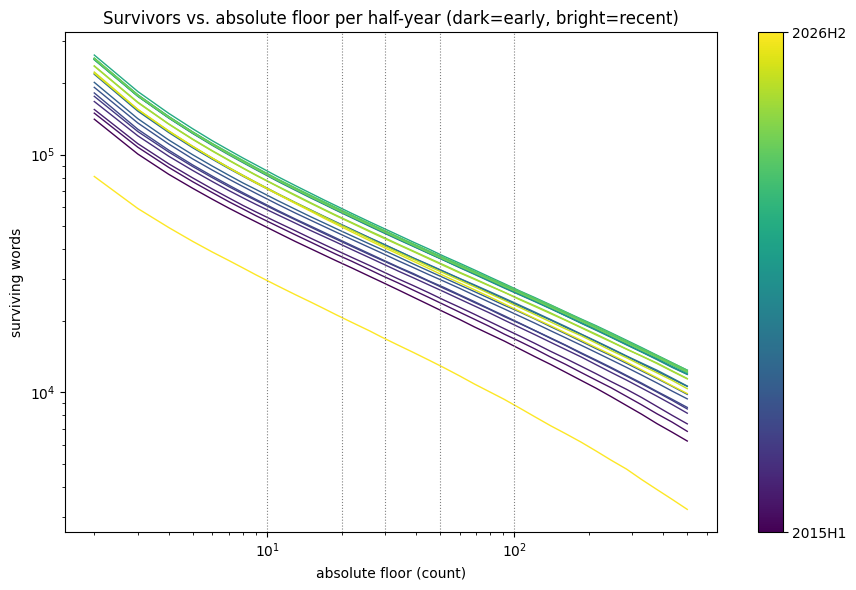

In [45]:
# Dense grid for a smooth curve (log-spaced over a useful range).
grid = np.unique(np.round(np.geomspace(2, 500, 40)).astype(int))
surv_grid = np.empty((len(half_years), grid.size), dtype=np.int64)
for i in range(len(half_years)):
    row = np.asarray(freq[i], dtype=np.int64)
    row = row[row > 0]
    # survivors(c) = count of cells with value >= c
    surv_grid[i] = np.array([(row >= c).sum() for c in grid])

fig, ax = plt.subplots(figsize=(9, 6))
cmap = plt.cm.viridis(np.linspace(0, 1, len(half_years)))
for i, h in enumerate(half_years):
    ax.plot(grid, surv_grid[i], color=cmap[i], lw=1)
for c in ABS_FLOORS:
    ax.axvline(c, color="grey", ls=":", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("absolute floor (count)")
ax.set_ylabel("surviving words")
ax.set_title(
    "Survivors vs. absolute floor per half-year "
    "(dark=early, bright=recent)"
)
sm = plt.cm.ScalarMappable(
    cmap="viridis",
    norm=plt.Normalize(vmin=0, vmax=len(half_years) - 1),
)
cbar = fig.colorbar(sm, ax=ax, ticks=[0, len(half_years) - 1])
cbar.ax.set_yticklabels([half_years[0], half_years[-1]])
plt.tight_layout()
plt.show()

## 6. How to read these tables

Pick a floor that satisfies, in priority order:

1. **Recall (section 4).** The floor must drop **zero** (or very few) known
   drug terms. For a recall-oriented filter this is the hard constraint. If
   a candidate floor drops real euphemisms, it is too high regardless of how
   clean the survivor counts look.
2. **Reliability (the gate's purpose).** The floor should be a count large
   enough that `hits_k / frequency` is a stable ratio. A common
   rule-of-thumb minimum for a proportion estimate is ~30 observations, so
   30 has a defensible power justification independent of the corpus — this
   is the clean reason to keep an absolute floor rather than a rate floor.
3. **Consistency (section 2, `rate_per_M`).** Check how much the implied
   rate swings across half-years. If a single absolute floor implies a
   hugely different rate in 2012 vs. the latest half-year, note it; if that
   swing matters for your downstream use, prefer a rate floor (section 3)
   whose implied counts still clear the reliability minimum in every
   half-year.

**Recommended shipped rule:** an absolute floor justified on reliability
grounds (the current `MIN_FREQ = 30` is reasonable if section 4 shows it
keeps the known terms), applied per-half-year exactly as
`postfilter_per_half_year` already does. Set it via `--min-freq` /
`MIN_FREQ`. Keep the rate view as the justification that the floor behaves
acceptably across the timeline — not as the shipped rule, unless the
consistency check in step 3 pushes you there.

Either rule is leakage-clean: each cell's decision uses only its own
half-year.